# Importing the dependencies

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data collection and Preprocessing

In [31]:
# loading the data from csv file to padas dataframe
car_df = pd.read_csv("cars dataset.csv")

In [32]:
# Inspecting the first five rows of the dataframe
car_df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [33]:
# checking the number of the rows and columns
print(car_df.columns.tolist())
print("Dataset shape:", car_df.shape)

['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
Dataset shape: (4340, 8)


In [34]:
# getting some information about the dataset
car_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [35]:
# checking the number of missing values
car_df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [36]:
# Check duplicate rows
print("Duplicate rows:", car_df.duplicated().sum())

Duplicate rows: 763


In [37]:

# Remove duplicate rows
car_df = car_df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", car_df.shape)
print("Remaining duplicates:", car_df.duplicated().sum())

Dataset shape after removing duplicates: (3577, 8)
Remaining duplicates: 0


In [38]:
# Fix inconsistent categorical values

# Remove leading and trailing spaces
categorical_cols = [
    "name", "fuel", "seller_type",
    "transmission", "owner"
]

for col in categorical_cols:
    car_df[col] = car_df[col].astype("string").str.strip()

# Standardize capitalization
for col in ["fuel", "seller_type", "transmission", "owner"]:
    car_df[col] = car_df[col].str.title()

# Verify unique values
print("Fuel types:", car_df["fuel"].unique())
print("Seller types:", car_df["seller_type"].unique())
print("Transmission types:", car_df["transmission"].unique())
print("Owner types:", car_df["owner"].unique())

Fuel types: <StringArray>
['Petrol', 'Diesel', 'Cng', 'Lpg', 'Electric']
Length: 5, dtype: string
Seller types: <StringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: string
Transmission types: <StringArray>
['Manual', 'Automatic']
Length: 2, dtype: string
Owner types: <StringArray>
[         'First Owner',         'Second Owner', 'Fourth & Above Owner',
          'Third Owner',       'Test Drive Car']
Length: 5, dtype: string


In [39]:
print("Final missing values:", car_df.isnull().sum().sum())
print("Final duplicate rows:", car_df.duplicated().sum())

display(car_df.head())

Final missing values: 0
Final duplicate rows: 0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [40]:
# Calculate car age
from datetime import datetime

# Get the current year automatically
current_year = datetime.now().year

# Calculate car age
car_df["car_age"] = current_year - car_df["year"]

# Display the result
display(car_df[["name", "year", "car_age"]].head(10))

,name,year,car_age
0,Maruti 800 AC,2007,19
1,Maruti Wagon R LXI Minor,2007,19
2,Hyundai Verna 1.6 SX,2012,14
3,Datsun RediGO T Option,2017,9
4,Honda Amaze VX i-DTEC,2014,12
5,Maruti Alto LX BSIII,2007,19
6,Hyundai Xcent 1.2 Kappa S,2016,10
7,Tata Indigo Grand Petrol,2014,12
8,Hyundai Creta 1.6 VTVT S,2015,11
9,Maruti Celerio Green VXI,2017,9


In [41]:
# Extract brand from car name
# Extract brand from car name
car_df["brand"] = car_df["name"].str.split().str[0].str.title()

# Display the result
display(car_df[["name", "brand"]].head(10))

,name,brand
0,Maruti 800 AC,Maruti
1,Maruti Wagon R LXI Minor,Maruti
2,Hyundai Verna 1.6 SX,Hyundai
3,Datsun RediGO T Option,Datsun
4,Honda Amaze VX i-DTEC,Honda
5,Maruti Alto LX BSIII,Maruti
6,Hyundai Xcent 1.2 Kappa S,Hyundai
7,Tata Indigo Grand Petrol,Tata
8,Hyundai Creta 1.6 VTVT S,Hyundai
9,Maruti Celerio Green VXI,Maruti


Car age column created: True


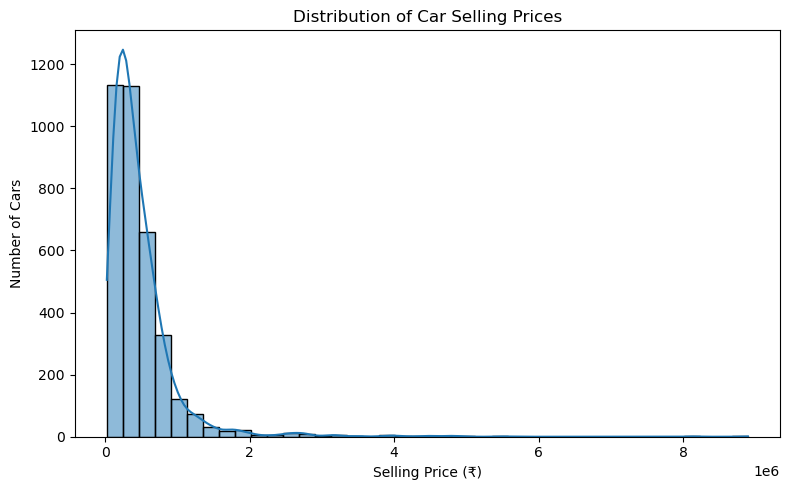

Brand column created: True

Updated dataset shape: (3577, 10)


,name,year,car_age,brand
0,Maruti 800 AC,2007,19,Maruti
1,Maruti Wagon R LXI Minor,2007,19,Maruti
2,Hyundai Verna 1.6 SX,2012,14,Hyundai
3,Datsun RediGO T Option,2017,9,Datsun
4,Honda Amaze VX i-DTEC,2014,12,Honda


In [42]:
# new features
print("Car age column created:", "car_age" in car_df.columns)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=car_df,
    x="selling_price",
    bins=40,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()
print("Brand column created:", "brand" in car_df.columns)

print("\nUpdated dataset shape:", car_df.shape)

display(
    car_df[["name", "year", "car_age", "brand"]].head()
)

# 1.Selling price distribution

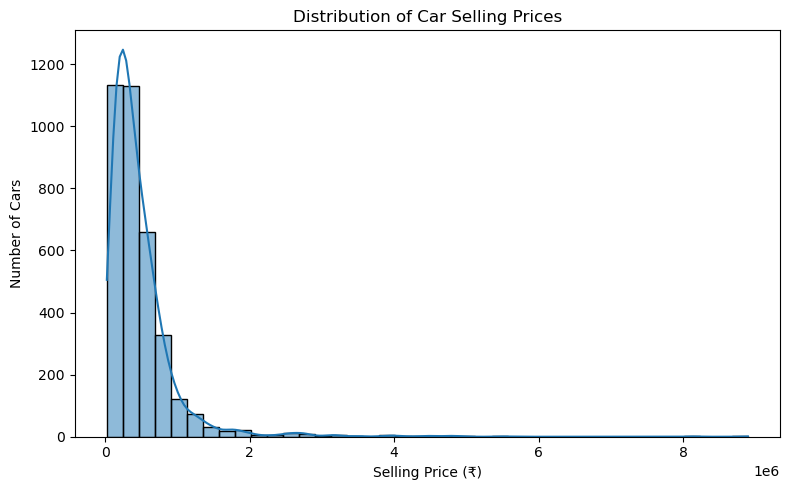

In [43]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=car_df,
    x="selling_price",
    bins=40,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


# 2. Selling price vs. fuel type

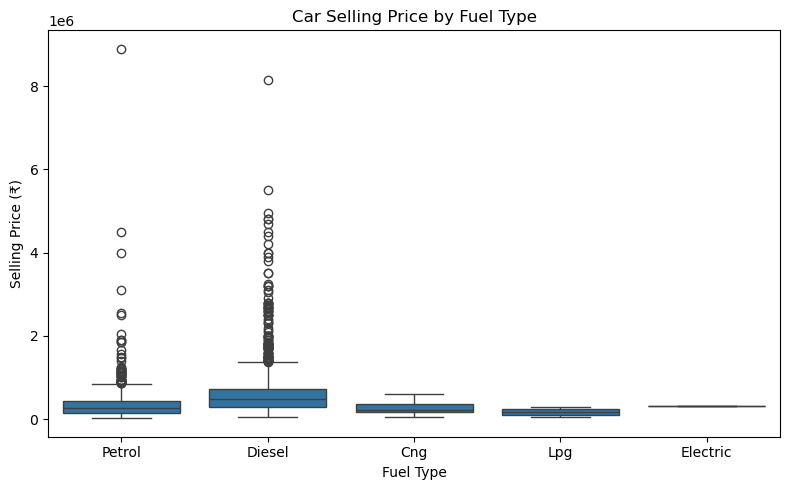

In [44]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=car_df,
    x="fuel",
    y="selling_price"
)

plt.title("Car Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()


# 3. Car age vs. selling price

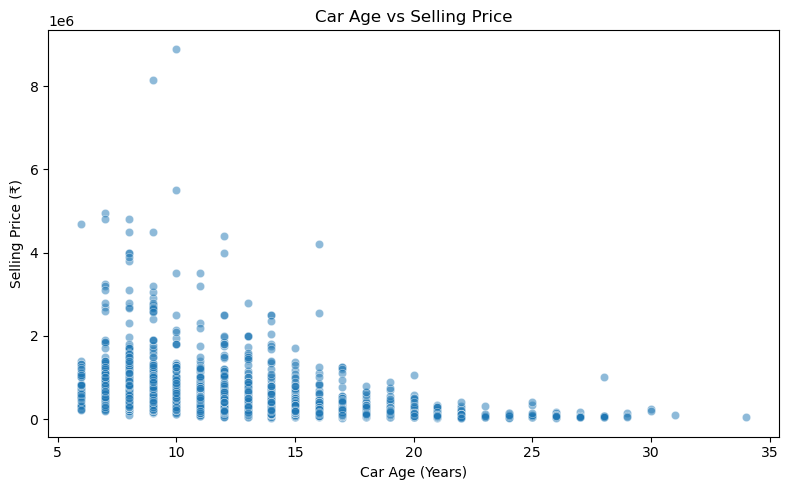

In [45]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=car_df,
    x="car_age",
    y="selling_price",
    alpha=0.5
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()


In [46]:

# Input features
X = car_df[
    [
        "brand",
        "car_age",
        "km_driven",
        "fuel",
        "seller_type",
        "transmission",
        "owner"
    ]
].copy()

# Target variable
y = car_df["selling_price"].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Input features shape: (3577, 7)
Target shape: (3577,)


,brand,car_age,km_driven,fuel,seller_type,transmission,owner
0,Maruti,19,70000,Petrol,Individual,Manual,First Owner
1,Maruti,19,50000,Petrol,Individual,Manual,First Owner
2,Hyundai,14,100000,Diesel,Individual,Manual,First Owner
3,Datsun,9,46000,Petrol,Individual,Manual,First Owner
4,Honda,12,141000,Diesel,Individual,Manual,Second Owner


Identify the categories of column

In [47]:

categorical_cols = [
    "brand",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

numerical_cols = [
    "car_age",
    "km_driven"
]

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)


Categorical columns: ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
Numerical columns: ['car_age', 'km_driven']


One-Hot Encoding

In [48]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessing for numerical columns
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_transformer, categorical_cols),
    ("num", numerical_transformer, numerical_cols)
])

print("Preprocessor created successfully!")


Preprocessor created successfully!


Correlation heatmap

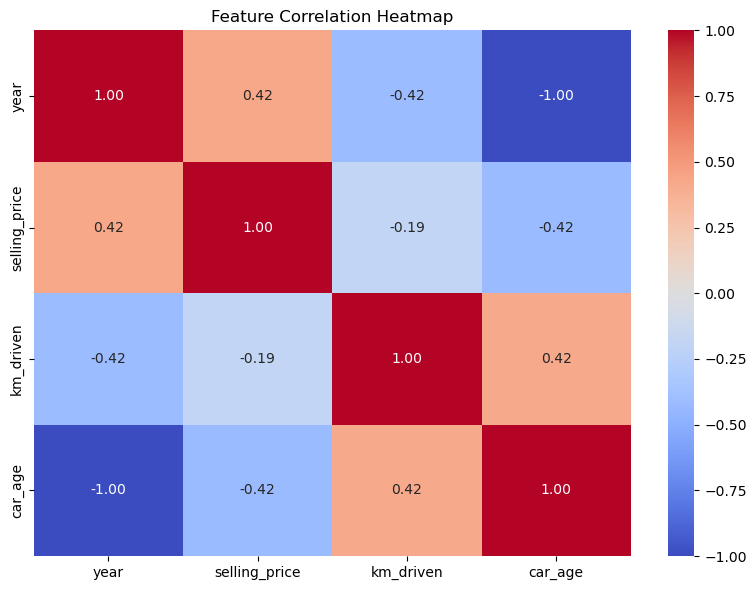

In [49]:

# Select numerical columns for correlation analysis
correlation_cols = [
    "year",
    "selling_price",
    "km_driven",
    "car_age"
]

correlation_matrix = car_df[correlation_cols].corr()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


# Spliting the data into Training data and Test data

In [50]:
# Dataset split

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (2861, 7)
Testing features: (716, 7)
Training target: (2861,)
Testing target: (716,)


Model training 

In [57]:

from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Linear Regression
lr_model = make_pipeline(preprocessor, LinearRegression())
lr_model.fit(X_train, y_train)

# Model 2: Random Forest Regressor
rf_model = make_pipeline(
    preprocessor,
    RandomForestRegressor(n_estimators=100, random_state=42)
)
rf_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")
print("Random Forest trained successfully!")


Linear Regression trained successfully!
Random Forest trained successfully!


# Evaluation

In [59]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Linear Regression Evaluation
print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2 Score:", r2_score(y_test, lr_pred))

print("\nRandom Forest Regressor")
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))


Linear Regression
MAE: 206368.4020881657
RMSE: 431734.1029725233
R2 Score: 0.42137523771854235

Random Forest Regressor
MAE: 158737.1814957293
RMSE: 366620.094192818
R2 Score: 0.5827495303139338


# Feature Importance Chart

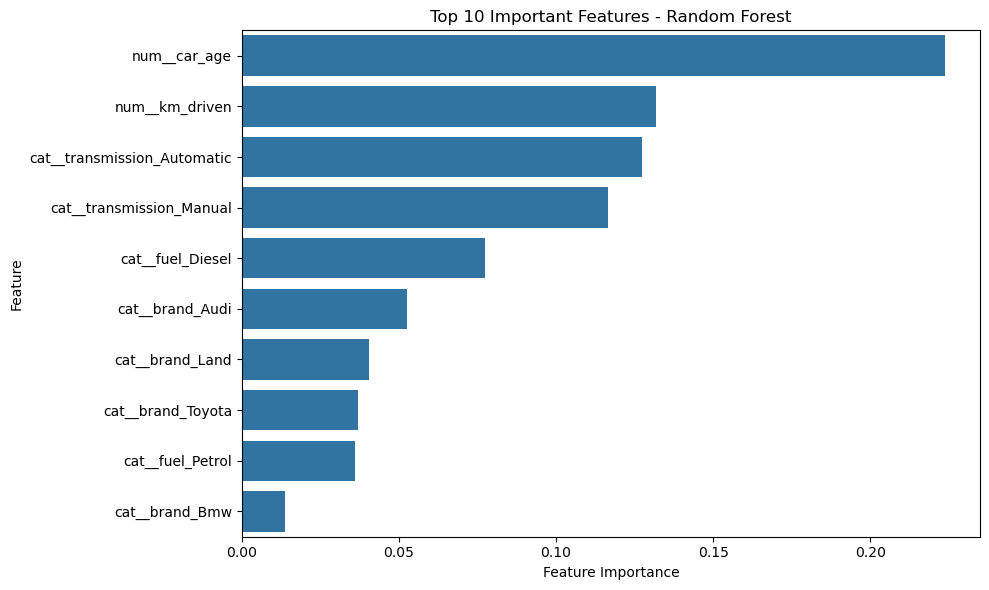

In [60]:
# Get the trained Random Forest model
rf = rf_model.named_steps["randomforestregressor"]

# Get feature names after One-Hot Encoding
feature_names = rf_model.named_steps["columntransformer"].get_feature_names_out()

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

# Select top 10 important features
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(10)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [61]:
import joblib

joblib.dump(rf_model, "car_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
